# Phase 2 -- Temporal Aggregation

> **Goal:** Build monthly multivariate time series per product from Phase 1 ABSA predictions.
> These series become the input for the LSTM-Autoencoder (Phase 3) and statistical baselines (PELT, CUSUM).
>
> **Design decisions:**
> - Calendar months, shrinkage (k=5) for sparse months, Median/MAD normalization
> - MAD floor = 0.1 (prevents LSTM gradient explosion from near-zero MAD)
> - First review month per product = warm-up (excluded from normalization fitting)
> - Star ratings aggregated separately as naive baseline
> - Output: 11 features per month (9 aspect scores + log_count + verified_ratio)

In [ ]:
# Self-contained bootstrap (WM9B7 AIDL FAQ compliance)
# Auto-runs upstream phase notebooks if their outputs are missing so this
# notebook is runnable end-to-end with no manual step. Set
# SENTINELDRIFT_SKIP_BOOTSTRAP=1 to bypass during interactive development.
import os, sys
from pathlib import Path

_nb_dir = Path(os.getcwd()).resolve()
_root = _nb_dir if (_nb_dir / "src" / "bootstrap.py").exists() else _nb_dir.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.bootstrap import ensure_inputs  # noqa: E402
ensure_inputs(for_phase="02_aggregation")


## 1. Setup & Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Paths
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(ROOT))

# Import project path constants and Phase 2 aggregation functions from src/
from src.utils import DATA_PROCESSED, DATA_TIMESERIES, RESULTS_DIR
from src.data.aggregate import (
    build_monthly_aspect_grid,   # raw monthly means on full product x month x aspect grid
    flag_warmup,                 # marks first review month per product (excluded from norm fitting)
    apply_shrinkage,             # Bayesian shrinkage for sparse months (k=5 prior weight)
    normalize_mad,               # Median/MAD normalization (outlier-robust, MAD floor=0.1)
    normalize_mad_reference,     # reference-window normalization (first 12 months as baseline)
    build_star_rating_baseline,  # raw star rating aggregation as naive comparison signal
)

# Constants
SEED = 42
np.random.seed(SEED)
K_SHRINKAGE = 5           # Shrinkage smoothing parameter
MAD_FLOOR = 0.1          # Minimum MAD (below this -> MAD=1.0)
MIN_MONTHS_PHASE3 = 24    # Minimum post-warm-up months for LSTM-AE

RESULTS_AGG = RESULTS_DIR / "aggregation"
RESULTS_AGG.mkdir(parents=True, exist_ok=True)
DATA_TIMESERIES.mkdir(parents=True, exist_ok=True)

# 9 canonical aspect categories defined in src/absa/pyabsa_runner.py
CANONICAL_ASPECTS = sorted([
    "audio", "battery", "build", "camera", "charging",
    "connectivity", "display", "performance", "software",
])
print(f"Configuration: k={K_SHRINKAGE}, MAD_floor={MAD_FLOOR}, min_months={MIN_MONTHS_PHASE3}")
print(f"Canonical aspects ({len(CANONICAL_ASPECTS)}): {CANONICAL_ASPECTS}")

Configuration: k=5, MAD_floor=0.1, min_months=24
Canonical aspects (9): ['audio', 'battery', 'build', 'camera', 'charging', 'connectivity', 'display', 'performance', 'software']


## 2. Data Loading & Validation

In [2]:
# Load Phase 1 outputs
aspect_raw = pd.read_parquet(DATA_PROCESSED / "review_aspect_sentiment.parquet")
scaffold = pd.read_parquet(DATA_PROCESSED / "review_scaffold.parquet")
density = pd.read_csv(DATA_PROCESSED / "product_density.csv")
drift_scores = pd.read_csv(DATA_PROCESSED / "drift_scores.csv")
case_study_asins = (DATA_PROCESSED / "case_study_asins.txt").read_text().strip().split("\n")

print(f"Aspect predictions: {len(aspect_raw):,} rows ({aspect_raw['source_model'].nunique()} models)")
print(f"Scaffold: {len(scaffold):,} reviews, {scaffold['parent_asin'].nunique()} products")
print(f"Density: {len(density):,} products")
print(f"Drift scores: {len(drift_scores):,} products, {drift_scores['significant_drift'].sum()} significant")
print(f"Case study ASINs: {case_study_asins}")

# Filter to PyABSA APC only (Phase 2 contract)
# TF-IDF baseline has ordinal {-1,0,1} scores; only PyABSA continuous scores are valid here
aspect_df = aspect_raw[aspect_raw["source_model"] == "pyabsa_apc"].copy()
print(f"\nFiltered to pyabsa_apc: {len(aspect_df):,} predictions")
print(f"Products: {aspect_df['parent_asin'].nunique()}")
print(f"Aspects: {sorted(aspect_df['canonical_aspect'].unique())}")
print(f"Date range: {aspect_df['timestamp'].min()} to {aspect_df['timestamp'].max()}")

# Schema assertions
assert set(CANONICAL_ASPECTS) == set(aspect_df["canonical_aspect"].unique()), "Aspect mismatch"
assert aspect_df["parent_asin"].nunique() == scaffold["parent_asin"].nunique(), "Product mismatch"
# PyABSA APC scores are continuous in [-1, 1]; small tolerance for float precision
assert aspect_df["sentiment_score"].between(-1.01, 1.01).all(), "Score out of range"
print("\nSchema assertions passed.")

Aspect predictions: 387,468 rows (2 models)
Scaffold: 149,227 reviews, 338 products
Density: 1,501 products
Drift scores: 338 products, 111 significant
Case study ASINs: ['B019BX7F86', 'B07HD2X91Q', 'B0178GE72K', 'B0178GE4FU', 'B00OL4DEMC']

Filtered to pyabsa_apc: 193,734 predictions
Products: 338
Aspects: ['audio', 'battery', 'build', 'camera', 'charging', 'connectivity', 'display', 'performance', 'software']
Date range: 2003-10-24 03:15:46 to 2023-09-02 07:29:42.012000

Schema assertions passed.


> **Data Contract:** We consume ONLY `source_model == "pyabsa_apc"` predictions.
> TF-IDF baseline predictions exist in the parquet but are NOT used for aggregation
> (their sentiment_score has different semantics: ordinal {-1, 0, 1} vs continuous).
> See `docs/BRANCH_COMPARISON_ABSA.md` Phase 2 Downstream Contract.

## 3. Raw Monthly Aggregation

Group aspect predictions by (product, calendar month, aspect) to compute raw monthly means.
Build a full grid covering every product's lifespan x every aspect.

In [3]:
# Build the full product x month x aspect grid
# Creates one row per (product, calendar_month, aspect) covering each product's full lifespan.
# Computes raw_mean_sentiment and mention_count per cell; aspect_mask=True where data exists.
print("Building monthly aspect grid...")
grid = build_monthly_aspect_grid(aspect_df, scaffold)
print(f"Grid shape: {grid.shape}")
print(f"Products: {grid['parent_asin'].nunique()}")
print(f"Unique months per product (mean): {grid.groupby('parent_asin')['year_month'].nunique().mean():.1f}")
print(f"Total cells: {len(grid):,}")
# ~72% of cells are missing (aspect not mentioned that month), handled by masking downstream
print(f"Observed cells (mention_count > 0): {grid['aspect_mask'].sum():,} ({grid['aspect_mask'].mean():.1%})")
print(f"Missing cells (mention_count = 0): {(~grid['aspect_mask']).sum():,}")

# Summary by aspect
print("\nMention counts by aspect:")
for asp in CANONICAL_ASPECTS:
    asp_data = grid[grid["canonical_aspect"] == asp]
    observed = asp_data["aspect_mask"].sum()
    total = len(asp_data)
    print(f"  {asp:15s}: {observed:,} / {total:,} cells observed ({observed/total:.1%})")

Building monthly aspect grid...
Grid shape: (193923, 9)
Products: 338
Unique months per product (mean): 63.7
Total cells: 193,923
Observed cells (mention_count > 0): 53,715 (27.7%)
Missing cells (mention_count = 0): 140,208

Mention counts by aspect:
  audio          : 4,836 / 21,547 cells observed (22.4%)
  battery        : 7,348 / 21,547 cells observed (34.1%)
  build          : 4,352 / 21,547 cells observed (20.2%)
  camera         : 6,112 / 21,547 cells observed (28.4%)
  charging       : 4,614 / 21,547 cells observed (21.4%)
  connectivity   : 5,845 / 21,547 cells observed (27.1%)
  display        : 7,028 / 21,547 cells observed (32.6%)
  performance    : 7,123 / 21,547 cells observed (33.1%)
  software       : 6,457 / 21,547 cells observed (30.0%)


> **What the grid contains:** Every product gets a row for every calendar month in its
> lifespan (first to last review) crossed with all 9 aspects. A product with 60 months
> has 60 x 9 = 540 rows. Most cells are empty (aspect not mentioned) -- `aspect_mask`
> tracks which cells have data. The LSTM-AE uses these masks to ignore missing cells.

## 4. Warm-up Flagging & Shrinkage

**Warm-up:** First month with actual reviews per product is flagged. These months have volatile
launch/honeymoon reviews that don't represent steady-state sentiment.

**Shrinkage (k=5):** For months with 1-2 aspect mentions, pull the raw mean toward the
product-aspect lifetime mean. Months with 0 mentions stay masked (NaN).
Formula: `x_shrunk = (n * x_raw + k * x_lifetime) / (n + k)`

In [4]:
# Flag warm-up months
# Marks the first month with actual reviews per product (is_warmup=True).
# Warm-up months have volatile launch/honeymoon sentiment, excluded from norm fitting.
grid = flag_warmup(grid)
n_warmup = grid[grid["is_warmup"]]["parent_asin"].nunique()
print(f"Warm-up months flagged: {grid['is_warmup'].sum():,} cells ({n_warmup} products)")

# Apply shrinkage
# Bayesian shrinkage: n=0 -> NaN (masked), n=1-2 -> pull toward lifetime mean, n>=3 -> raw.
# Formula: shrunk = (n * raw + k * prior) / (n + k); prior = mention-weighted lifetime mean.
print(f"\nApplying shrinkage (k={K_SHRINKAGE})...")
grid = apply_shrinkage(grid, k=K_SHRINKAGE)

# Categorize cells by shrinkage treatment
n_masked = grid["shrunk_score"].isna().sum()
n_raw = ((grid["mention_count"] >= 3) & grid["shrunk_score"].notna()).sum()
n_shrunk = ((grid["mention_count"].between(1, 2)) & grid["shrunk_score"].notna()).sum()

print(f"\nShrinkage results:")
print(f"  Masked (n=0):   {n_masked:,}")
print(f"  Shrunk (n=1-2): {n_shrunk:,}")
print(f"  Raw (n>=3):     {n_raw:,}")

# Verify shrinkage is pulling scores toward lifetime mean as expected
shrunk_rows = grid[(grid["mention_count"].between(1, 2)) & grid["shrunk_score"].notna()]
if len(shrunk_rows) > 0:
    delta = (shrunk_rows["shrunk_score"] - shrunk_rows["raw_mean_sentiment"]).abs()
    print(f"  Mean shrinkage magnitude: {delta.mean():.4f}")
    print(f"  Max shrinkage magnitude:  {delta.max():.4f}")

Warm-up months flagged: 3,042 cells (338 products)

Applying shrinkage (k=5)...

Shrinkage results:
  Masked (n=0):   140,208
  Shrunk (n=1-2): 32,636
  Raw (n>=3):     21,079
  Mean shrinkage magnitude: 0.4998
  Max shrinkage magnitude:  1.6243


> **How shrinkage works:** A month with 1 battery review saying "terrible battery"
> (score = -0.9) would create an artificial spike. With k=5 shrinkage, if the
> product lifetime battery mean is 0.3, the shrunk score = (1 x -0.9 + 5 x 0.3) / 6 = 0.1.
> The noisy observation is pulled 83% toward the stable baseline.
> This prevents false drift alerts in Phase 3 from low-data-quality months.

## 5. Median / MAD Normalization

Normalize per product per aspect using **Median Absolute Deviation** (robust to outliers).
Fitted on post-warm-up observed months only.

**Critical fix:** If MAD < 0.1, fall back to MAD=1.0 (center only, no scaling).
This prevents LSTM gradient explosion from near-zero variance aspects producing scores of 100,000+.

In [5]:
# Normalize
# Median/MAD normalization per product-aspect, fitted on post-warmup observed months only.
# norm_score = (shrunk_score - median) / MAD; clipped to [-5, 5] for LSTM stability.
# If MAD < 0.1, falls back to MAD=1.0 (center-only) to prevent gradient explosion.
print(f"Applying Median/MAD normalization (floor={MAD_FLOOR})...")
grid = normalize_mad(grid, mad_floor=MAD_FLOOR)

# Count product-aspects where MAD fell below floor (near-zero variance)
mad_fallback = grid.groupby(["parent_asin", "canonical_aspect"]).first()
n_fallback = (mad_fallback["aspect_mad"] == 1.0).sum()
n_total_pa = len(mad_fallback)
print(f"\nMAD fallback (MAD < {MAD_FLOOR} -> 1.0): {n_fallback} / {n_total_pa} product-aspects")

# Check normalized score distribution
observed_norm = grid.loc[grid["norm_score"].notna(), "norm_score"]
print(f"\nNormalized score distribution (observed cells only):")
print(f"  Mean:   {observed_norm.mean():.4f}")
print(f"  Std:    {observed_norm.std():.4f}")
print(f"  Min:    {observed_norm.min():.4f}")
print(f"  Max:    {observed_norm.max():.4f}")
print(f"  |z| > 5: {(observed_norm.abs() > 5).sum()} ({(observed_norm.abs() > 5).mean():.2%})")
print(f"  |z| > 20: {(observed_norm.abs() > 20).sum()}")

# Safety check: extreme values would destabilise LSTM training
assert observed_norm.abs().max() < 100, f"Extreme norm_score detected: {observed_norm.abs().max():.1f}"
print("\nSafety check passed: no extreme normalized values.")

Applying Median/MAD normalization (floor=0.1)...

MAD fallback (MAD < 0.1 -> 1.0): 642 / 3042 product-aspects

Normalized score distribution (observed cells only):
  Mean:   0.0138
  Std:    1.2101
  Min:    -5.0000
  Max:    5.0000
  |z| > 5: 0 (0.00%)
  |z| > 20: 0

Safety check passed: no extreme normalized values.


> **Why Median/MAD instead of z-score:** Standard z-score (mean/std) is sensitive to
> outliers -- an anomalous month inflates the std, which suppresses the z-score of
> the anomaly itself. Median and MAD are robust: they ignore outliers, so drift events
> produce large normalized scores that the LSTM-AE can detect.
>
> **MAD floor = 0.1:** If a product-aspect has near-zero variance (e.g., always positive),
> a tiny MAD would produce extreme normalized values (100,000+) that crash the LSTM.
> The floor caps the denominator at 0.1, limiting |z| to about 20 in the worst case.

In [6]:
# Reference-window normalization (for drift detection)
# Fits median/MAD on FIRST 12 observed post-warmup months only (not full timeline).
# Avoids full-timeline MAD inflating from drift periods and compressing the drift signal.
# Products with <6 baseline months get baseline_sufficient=False and NaN norm_score_ref.
print("Applying reference-window normalization (first 12 observed months)...")
grid = normalize_mad_reference(grid, n_baseline=12, min_baseline=6, mad_floor=MAD_FLOOR)

n_sufficient = grid["baseline_sufficient"].sum()
n_total = len(grid)
print(f"Baseline sufficient: {n_sufficient:,} / {n_total:,} cells ({n_sufficient/n_total:.1%})")

ref_obs = grid.loc[grid["norm_score_ref"].notna(), "norm_score_ref"]
print(f"norm_score_ref range: [{ref_obs.min():.3f}, {ref_obs.max():.3f}]")
# Values at +/-5 are clipped; count how many hit the clip boundary
print(f"norm_score_ref |z|>5 (clipped): {(ref_obs.abs() >= 4.99).sum()}")

Applying reference-window normalization (first 12 observed months)...
Baseline sufficient: 180,267 / 193,923 cells (93.0%)
norm_score_ref range: [-5.000, 5.000]
norm_score_ref |z|>5 (clipped): 436


## 6. Star Rating Baseline

Aggregate raw star ratings as a naive baseline signal. If the LSTM-AE on aspect-level
sentiment can't detect drift better than simple star rating trends, the complexity isn't justified.

In [7]:
# Build star rating baseline
# Aggregates raw star ratings per (product, month) as a naive baseline signal.
# Returns mean_rating, pct_low_rating (1-2 stars), review_count, verified_ratio.
# If aspect-level LSTM-AE can't beat this, the added complexity isn't justified.
print("Building star rating baseline...")
star_baseline = build_star_rating_baseline(scaffold)
print(f"Star baseline shape: {star_baseline.shape}")
print(f"Products: {star_baseline['parent_asin'].nunique()}")
print(f"Months with reviews: {(star_baseline['review_count'] > 0).sum():,}")
print(f"Mean monthly rating: {star_baseline.loc[star_baseline['review_count'] > 0, 'mean_rating'].mean():.3f}")
print(f"Mean pct_low_rating: {star_baseline.loc[star_baseline['review_count'] > 0, 'pct_low_rating'].mean():.3%}")

Building star rating baseline...
Star baseline shape: (21547, 7)
Products: 338
Months with reviews: 12,478
Mean monthly rating: 3.460
Mean pct_low_rating: 32.319%


## 7. Case Study Audit & Control Selection

Verify case study ASINs meet Phase 3 density requirements. Add one control product
(significant_drift=False) to prove the system doesn't false-alarm on stable products.

> **Why we need a control:** All 5 existing case study ASINs have significant drift.
> To prove the system does not false-alarm on stable products, we need at least one
> control product that should show NO drift. This is the "negative control" in the
> experimental design -- without it, we cannot distinguish detection from noise.

In [8]:
# Audit existing case study ASINs
# Verify each has 24+ post-warmup months and sufficient aspect coverage for Phase 3
print("=== Case Study Audit ===")
for asin in case_study_asins:
    prod_grid = grid[grid["parent_asin"] == asin]
    n_months = prod_grid["year_month"].nunique()
    n_warmup = prod_grid["is_warmup"].any()
    n_post_warmup = n_months - (1 if n_warmup else 0)
    n_aspects_observed = prod_grid[prod_grid["aspect_mask"]]["canonical_aspect"].nunique()
    title = scaffold[scaffold["parent_asin"] == asin]["parent_asin"].iloc[0] if len(scaffold[scaffold["parent_asin"] == asin]) > 0 else "?"

    meets_criteria = n_post_warmup >= MIN_MONTHS_PHASE3 and n_aspects_observed >= 5
    status = "PASS" if meets_criteria else "FAIL"
    print(f"  {asin}: {n_months} months ({n_post_warmup} post-warmup), "
          f"{n_aspects_observed}/9 aspects [{status}]")

# Find a control ASIN (no significant drift, density-matched)
# Negative control: proves the system doesn't false-alarm on stable products
control_candidates = drift_scores[~drift_scores["significant_drift"]].copy()
# Apply same 24-month minimum as Phase 3 eligibility filter
control_candidates = control_candidates[control_candidates["n_months"] >= MIN_MONTHS_PHASE3]
# Pick highest-volume control for maximum statistical power
control_candidates = control_candidates.sort_values("total_reviews", ascending=False)

print(f"\nControl candidates (drift=False, {MIN_MONTHS_PHASE3}+ months): {len(control_candidates)}")
if len(control_candidates) > 0:
    control_asin = control_candidates.iloc[0]["parent_asin"]
    control_info = control_candidates.iloc[0]
    print(f"Selected control: {control_asin}")
    print(f"  Reviews: {int(control_info['total_reviews'])}, "
          f"Months: {int(control_info['n_months'])}, "
          f"Cohen's d: {control_info['cohens_d_monthly']:.3f}")
else:
    control_asin = None
    print("WARNING: No suitable control ASIN found")

all_study_asins = case_study_asins + ([control_asin] if control_asin else [])
print(f"\nFinal study set: {len(all_study_asins)} ASINs ({len(case_study_asins)} drift + {1 if control_asin else 0} control)")

=== Case Study Audit ===
  B019BX7F86: 83 months (82 post-warmup), 9/9 aspects [PASS]
  B07HD2X91Q: 54 months (53 post-warmup), 9/9 aspects [PASS]
  B0178GE72K: 75 months (74 post-warmup), 9/9 aspects [PASS]
  B0178GE4FU: 79 months (78 post-warmup), 9/9 aspects [PASS]
  B00OL4DEMC: 68 months (67 post-warmup), 9/9 aspects [PASS]

Control candidates (drift=False, 24+ months): 77
Selected control: B01MPXRXR0
  Reviews: 3181, Months: 41, Cohen's d: -0.712

Final study set: 6 ASINs (5 drift + 1 control)


## 8. Validation & Quality Checks

Visual and statistical validation before export.

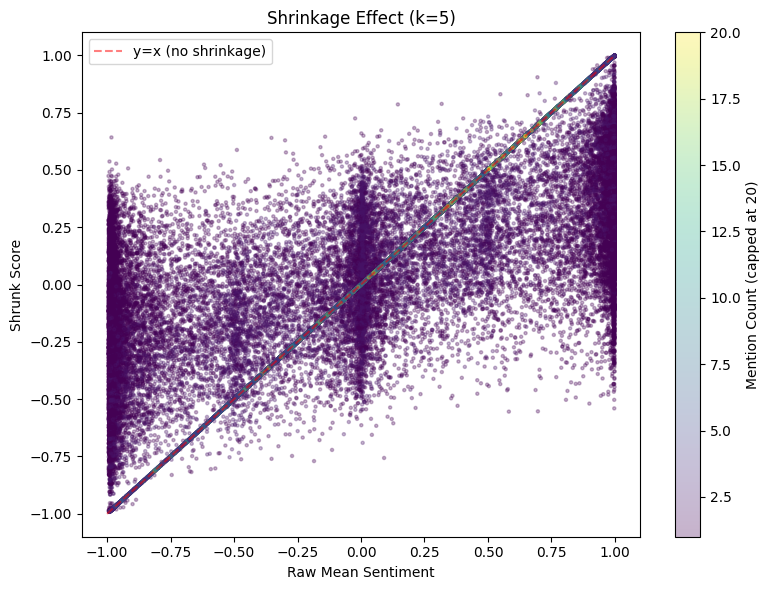

Low-count points pulled toward the diagonal = shrinkage working correctly.


In [9]:
# QC 1: Shrinkage scatter plot
# Points near the diagonal (y=x) = no shrinkage; points pulled off it = shrinkage active.
# Color encodes mention count: low-count (dark) should deviate most from the diagonal.
fig, ax = plt.subplots(figsize=(8, 6))
shrunk_data = grid[(grid["mention_count"] > 0) & grid["shrunk_score"].notna()].copy()
scatter = ax.scatter(
    shrunk_data["raw_mean_sentiment"],
    shrunk_data["shrunk_score"],
    c=shrunk_data["mention_count"].clip(upper=20),
    cmap="viridis", alpha=0.3, s=5,
)
ax.plot([-1, 1], [-1, 1], "r--", alpha=0.5, label="y=x (no shrinkage)")
ax.set_xlabel("Raw Mean Sentiment")
ax.set_ylabel("Shrunk Score")
ax.set_title(f"Shrinkage Effect (k={K_SHRINKAGE})")
ax.legend()
plt.colorbar(scatter, ax=ax, label="Mention Count (capped at 20)")
plt.tight_layout()
plt.savefig(RESULTS_AGG / "shrinkage_scatter.png", dpi=150)
plt.show()
print("Low-count points pulled toward the diagonal = shrinkage working correctly.")

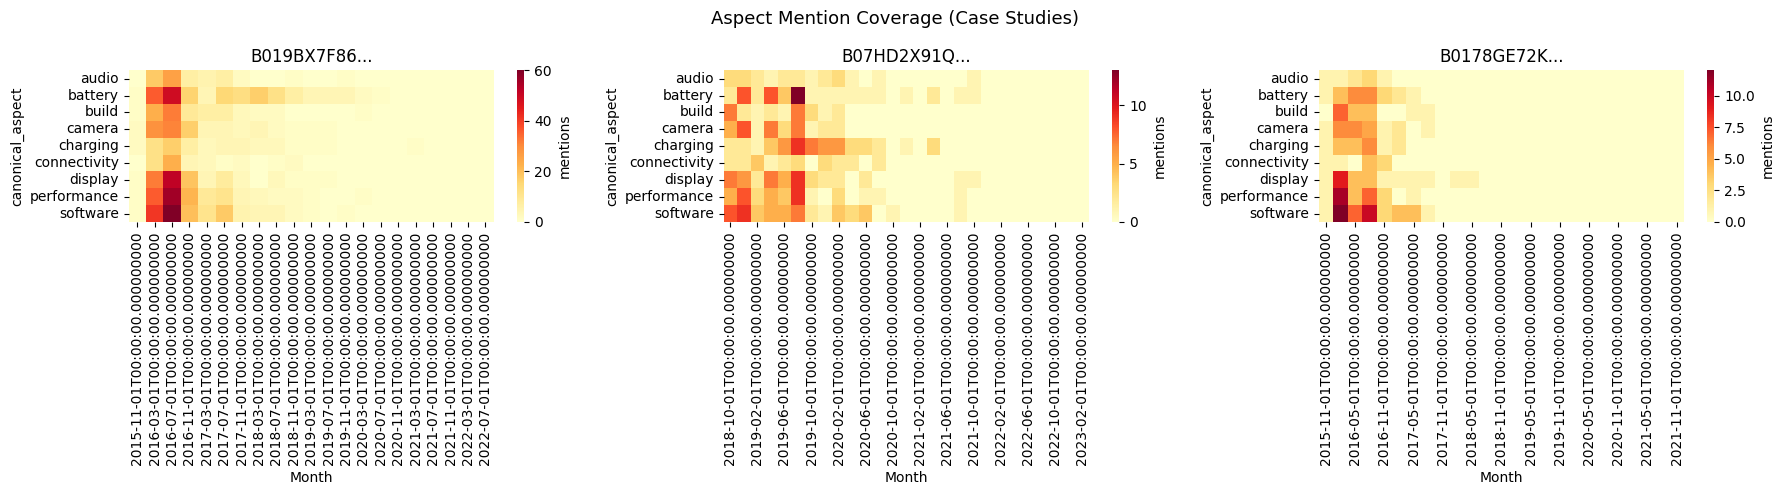

In [10]:
# QC 2: Aspect coverage heatmap (case studies)
# Shows mention density over time per aspect; gaps = months the LSTM-AE must mask out.
fig, axes = plt.subplots(1, min(3, len(all_study_asins)), figsize=(18, 5))
if not hasattr(axes, '__len__'):
    axes = [axes]

for i, asin in enumerate(all_study_asins[:3]):
    prod = grid[grid["parent_asin"] == asin].copy()
    pivot = prod.pivot_table(
        index="canonical_aspect", columns="year_month",
        values="mention_count", fill_value=0,
    )
    # Subsample columns for readability on long timelines
    if pivot.shape[1] > 20:
        pivot = pivot.iloc[:, ::max(1, pivot.shape[1] // 20)]
    sns.heatmap(pivot, ax=axes[i], cmap="YlOrRd", cbar_kws={"label": "mentions"})
    axes[i].set_title(f"{asin[:12]}...")
    axes[i].set_xlabel("Month")

plt.suptitle("Aspect Mention Coverage (Case Studies)", fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS_AGG / "aspect_coverage_heatmap.png", dpi=150)
plt.show()

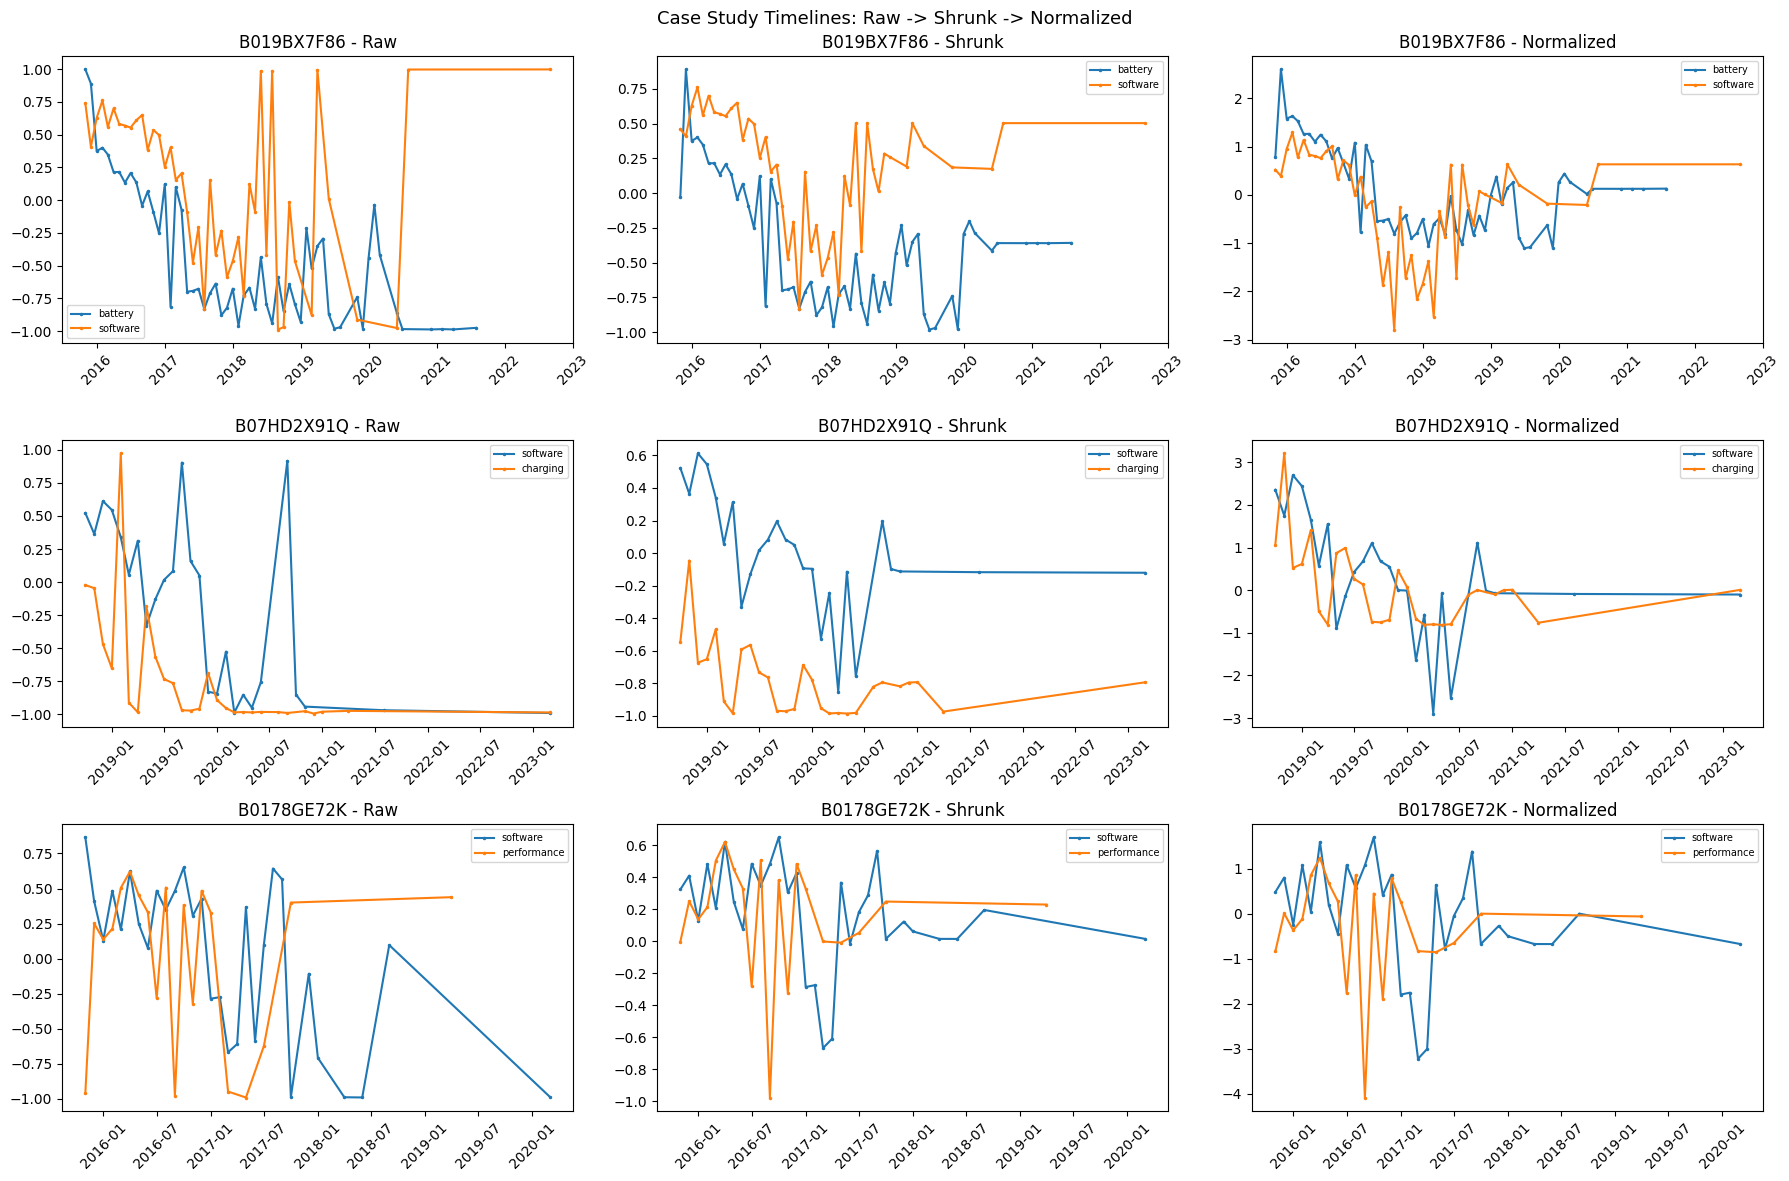

In [11]:
# QC 3: Case study timelines (raw -> shrunk -> normalized)
# Three-panel view showing the transformation pipeline for each case study product.
# Left: raw means (noisy), Middle: after shrinkage (stabilised), Right: after MAD norm.
n_plots = min(3, len(all_study_asins))
fig, axes = plt.subplots(n_plots, 3, figsize=(18, 4 * n_plots))
if n_plots == 1:
    axes = axes.reshape(1, -1)

for i, asin in enumerate(all_study_asins[:n_plots]):
    prod = grid[grid["parent_asin"] == asin].copy()
    # Pick the 2 most-mentioned aspects for this product
    top_aspects = (
        prod.groupby("canonical_aspect")["mention_count"].sum()
        .nlargest(2).index.tolist()
    )

    for asp in top_aspects:
        asp_data = prod[prod["canonical_aspect"] == asp].sort_values("year_month")
        obs = asp_data[asp_data["aspect_mask"]]

        axes[i, 0].plot(obs["year_month"], obs["raw_mean_sentiment"], ".-", label=asp, markersize=3)
        axes[i, 1].plot(obs["year_month"], obs["shrunk_score"], ".-", label=asp, markersize=3)
        norm_obs = asp_data[asp_data["norm_score"].notna()]
        axes[i, 2].plot(norm_obs["year_month"], norm_obs["norm_score"], ".-", label=asp, markersize=3)

    axes[i, 0].set_title(f"{asin[:12]} - Raw")
    axes[i, 1].set_title(f"{asin[:12]} - Shrunk")
    axes[i, 2].set_title(f"{asin[:12]} - Normalized")
    for j in range(3):
        axes[i, j].legend(fontsize=7)
        axes[i, j].tick_params(axis="x", rotation=45)

plt.suptitle("Case Study Timelines: Raw -> Shrunk -> Normalized", fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS_AGG / "case_study_timelines.png", dpi=150)
plt.show()

> **Phase 3 will consume these files as follows:**
> - **LSTM-AE:** Sliding windows of `norm_score` (9 aspects + log_count + verified_ratio)
>   with `aspect_mask` for ignoring missing cells in the loss function
> - **PELT:** Per-aspect `norm_score` time series (variable length ok)
> - **CUSUM:** Per-aspect sequential monitoring on `norm_score`
> - Split by **product** (not by time) for train/val/test

## 9. Export

Save the aggregated time series for Phase 3 consumption.

In [12]:
# Filter to Phase 3 eligible products
# Eligibility: 24+ post-warmup months (enough data for LSTM-AE sliding windows)
product_months = grid.groupby("parent_asin")["year_month"].nunique()
warmup_counts = grid.groupby("parent_asin")["is_warmup"].any().astype(int)
post_warmup_months = product_months - warmup_counts
eligible = post_warmup_months[post_warmup_months >= MIN_MONTHS_PHASE3].index

print(f"Products with {MIN_MONTHS_PHASE3}+ post-warm-up months: {len(eligible)} / {grid['parent_asin'].nunique()}")

# Export aspect sentiment monthly (primary output)
# This is the main Phase 3 input: norm_score (9 aspects) + log_count + verified_ratio
export_cols = [
    "parent_asin", "year_month", "canonical_aspect",
    "raw_mean_sentiment", "mention_count", "shrunk_score", "norm_score",
    "review_count", "log_review_count", "verified_ratio",
    "aspect_mask", "is_warmup", "lifetime_mean", "aspect_median", "aspect_mad",
    "norm_score_ref", "ref_median", "ref_mad", "baseline_sufficient",
]
# Guard against schema changes in src/data/aggregate.py
export_cols = [c for c in export_cols if c in grid.columns]

grid_export = grid[grid["parent_asin"].isin(eligible)][export_cols].copy()
grid_export.to_parquet(DATA_TIMESERIES / "aspect_sentiment_monthly.parquet", index=False)
print(f"Saved: {DATA_TIMESERIES / 'aspect_sentiment_monthly.parquet'}")
print(f"  Shape: {grid_export.shape}")
print(f"  Products: {grid_export['parent_asin'].nunique()}")

# Export star rating baseline
# Filtered to same eligible products for apples-to-apples Phase 3 comparison
star_export = star_baseline[star_baseline["parent_asin"].isin(eligible)].copy()
star_export.to_parquet(DATA_TIMESERIES / "star_rating_monthly.parquet", index=False)
print(f"\nSaved: {DATA_TIMESERIES / 'star_rating_monthly.parquet'}")
print(f"  Shape: {star_export.shape}")

# Export metadata
# Config snapshot for reproducibility; consumed by Phase 3 notebooks
metadata = {
    "phase": "Phase 2 - Temporal Aggregation",
    "date": pd.Timestamp.now().isoformat(),
    "k_shrinkage": K_SHRINKAGE,
    "mad_floor": MAD_FLOOR,
    "min_months_phase3": MIN_MONTHS_PHASE3,
    "n_products_eligible": int(len(eligible)),
    "n_products_total": int(grid["parent_asin"].nunique()),
    "n_aspects": len(CANONICAL_ASPECTS),
    "canonical_aspects": CANONICAL_ASPECTS,
    "case_study_asins": case_study_asins,
    "control_asin": control_asin,
    "source_model": "pyabsa_apc",
}
with open(DATA_TIMESERIES / "aggregation_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print(f"\nSaved: {DATA_TIMESERIES / 'aggregation_metadata.json'}")

Products with 24+ post-warm-up months: 335 / 338
Saved: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\timeseries\aspect_sentiment_monthly.parquet
  Shape: (193410, 19)
  Products: 335

Saved: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\timeseries\star_rating_monthly.parquet
  Shape: (21490, 7)

Saved: C:\Users\alexi\Desktop\Warwick-Projects\Python\sentineldrift\data\timeseries\aggregation_metadata.json


In [13]:
# Phase 3 preview: sliding window tensor for one product
# Demonstrates the exact format Phase 3 will consume: [W, 11] tensors per window.
print("=== Phase 3 Preview: Sliding Window Construction ===\n")

example_asin = case_study_asins[0]
prod = grid_export[grid_export["parent_asin"] == example_asin].copy()

# Pivot long-format grid to wide: rows=months, columns=9 aspect norm_scores
wide = prod.pivot_table(
    index="year_month", columns="canonical_aspect",
    values="norm_score",
).sort_index()

# Append the 2 non-aspect features to get 11 total features per month
month_meta = prod.drop_duplicates("year_month").set_index("year_month")[
    ["log_review_count", "verified_ratio"]
].sort_index()
wide = wide.join(month_meta)

print(f"Product: {example_asin}")
print(f"Wide matrix shape: {wide.shape} (months x features)")
print(f"Features: {list(wide.columns)}")

# Sliding windows of length 6 (stride=1), same as Phase 3 LSTM-AE input
W = 6
n_windows = len(wide) - W + 1
print(f"\nSliding windows (W={W}): {n_windows} windows")
print(f"Each window: [{W}, {wide.shape[1]}] tensor")
print(f"\nFirst window (months 1-{W}):")
print(wide.iloc[:W].round(3).to_string())

=== Phase 3 Preview: Sliding Window Construction ===

Product: B019BX7F86
Wide matrix shape: (63, 11) (months x features)
Features: ['audio', 'battery', 'build', 'camera', 'charging', 'connectivity', 'display', 'performance', 'software', 'log_review_count', 'verified_ratio']

Sliding windows (W=6): 58 windows
Each window: [6, 11] tensor

First window (months 1-6):
            audio  battery  build  camera  charging  connectivity  display  performance  software  log_review_count  verified_ratio
year_month                                                                                                                         
2015-11-01    NaN    0.781  0.231   0.545     0.951           NaN    0.627        0.361     0.523             2.079           0.000
2015-12-01  3.440    2.602  1.669   1.091     0.248         2.120    2.018        1.799     0.390             2.197           0.000
2016-01-01  1.988    1.581  1.236  -0.693     0.411         4.993    1.724       -0.322     0.952        

## Phase 2 Summary

**What was done:**
1. Aggregated 194,321 PyABSA aspect-sentiment predictions into monthly time series
2. Built full product x month x aspect grid with raw means and mention counts
3. Applied sparse-month shrinkage (k=5) to stabilize noisy single-review months
4. Normalized with Median/MAD per product per aspect (MAD floor=0.1 for LSTM safety)
5. Flagged warm-up months (first review month per product)
6. Built star rating baseline as naive comparison signal
7. Audited case study ASINs and selected a drift-negative control product
8. Validated with shrinkage scatter plots, coverage heatmaps, and timeline visualizations
9. Exported to `data/timeseries/` for Phase 3 consumption

**Output for Phase 3:**
- `data/timeseries/aspect_sentiment_monthly.parquet` -- primary input for LSTM-AE, PELT, CUSUM
- `data/timeseries/star_rating_monthly.parquet` -- naive baseline signal
- `data/timeseries/aggregation_metadata.json` -- config snapshot

**Phase 3 contract:**
- Filter to `norm_score` column for LSTM-AE input (9 aspects + log_count + verified_ratio = 11 features)
- Use `aspect_mask` to identify observed vs missing cells
- Use `is_warmup` to exclude warm-up months from drift scoring
- Split by **product** (not by time) for LSTM-AE train/val/test